In [6]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import mmlp

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset, vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

bow_encoder = clslib.BagOfWords(bpe_tokenizer.get_vocab(), bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
hidden_dim=128
hidden_dim_2=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['modMLP_bow-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/modMLP_bow-enc/seed-{seed}"
    my_classifiers['modMLP_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bow_encoder,
            model_option='mmlp',
            save_to=run_folder,
            mmlp_args={
                'hidden_dim': hidden_dim,
                'hidden_dim_2': hidden_dim_2,
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.711 seconds
Dataloader done! Time taken: 0.055 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\mmlp.py:75: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.6773 | train acc: 0.5790 | val loss: 0.6671 | val acc: 0.5969
Epoch 02 | train loss: 0.6662 | train acc: 0.5954 | val loss: 0.6644 | val acc: 0.5986
Epoch 03 | train loss: 0.6610 | train acc: 0.6015 | val loss: 0.6642 | val acc: 0.5980
Epoch 04 | train loss: 0.6570 | train acc: 0.6049 | val loss: 0.6578 | val acc: 0.6053
Epoch 05 | train loss: 0.6533 | train acc: 0.6105 | val loss: 0.6560 | val acc: 0.6099
Epoch 06 | train loss: 0.6483 | train acc: 0.6157 | val loss: 0.6543 | val acc: 0.6094
Epoch 07 | train loss: 0.6459 | train acc: 0.6192 | val loss: 0.6547 | val acc: 0.6030
Epoch 08 | train loss: 0.6433 | train acc: 0.6222 | val loss: 0.6517 | val acc: 0.6130
Epoch 09 | train loss: 0.6388 | train acc: 0.6264 | val loss: 0.6522 | val acc: 0.6107
Epoch 10 | train loss: 0.6369 | train acc: 0.6279 | val loss: 0.6501 | val acc: 0.6190
Training done! Time taken: 95.356 seconds
Transforming documents...
Document transformation done! Time taken: 3.694 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6799 | train acc: 0.5734 | val loss: 0.6612 | val acc: 0.6070
Epoch 02 | train loss: 0.6669 | train acc: 0.5916 | val loss: 0.6604 | val acc: 0.6099
Epoch 03 | train loss: 0.6626 | train acc: 0.5983 | val loss: 0.6558 | val acc: 0.6105
Epoch 04 | train loss: 0.6582 | train acc: 0.6030 | val loss: 0.6531 | val acc: 0.6181
Epoch 05 | train loss: 0.6550 | train acc: 0.6063 | val loss: 0.6554 | val acc: 0.6037
Epoch 06 | train loss: 0.6519 | train acc: 0.6105 | val loss: 0.6470 | val acc: 0.6227
Epoch 07 | train loss: 0.6479 | train acc: 0.6147 | val loss: 0.6471 | val acc: 0.6230
Epoch 08 | train loss: 0.6457 | train acc: 0.6164 | val loss: 0.6455 | val acc: 0.6223
Epoch 09 | train loss: 0.6417 | train acc: 0.6230 | val loss: 0.6402 | val acc: 0.6250
Epoch 10 | train loss: 0.6392 | train acc: 0.6241 | val loss: 0.6399 | val acc: 0.6284
Training done! Time taken: 88.594 seconds
Transforming documents...
Document transformation done! Time taken: 3.833 seconds
Datalo

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6792 | train acc: 0.5749 | val loss: 0.6704 | val acc: 0.5872
Epoch 02 | train loss: 0.6654 | train acc: 0.5952 | val loss: 0.6642 | val acc: 0.5960
Epoch 03 | train loss: 0.6608 | train acc: 0.6015 | val loss: 0.6582 | val acc: 0.6015
Epoch 04 | train loss: 0.6572 | train acc: 0.6064 | val loss: 0.6588 | val acc: 0.5979
Epoch 05 | train loss: 0.6539 | train acc: 0.6099 | val loss: 0.6549 | val acc: 0.6062
Epoch 06 | train loss: 0.6505 | train acc: 0.6131 | val loss: 0.6572 | val acc: 0.6026
Epoch 07 | train loss: 0.6477 | train acc: 0.6176 | val loss: 0.6501 | val acc: 0.6049
Epoch 08 | train loss: 0.6450 | train acc: 0.6193 | val loss: 0.6495 | val acc: 0.6118
Epoch 09 | train loss: 0.6407 | train acc: 0.6239 | val loss: 0.6479 | val acc: 0.6112
Epoch 10 | train loss: 0.6381 | train acc: 0.6280 | val loss: 0.6448 | val acc: 0.6158
Training done! Time taken: 94.344 seconds


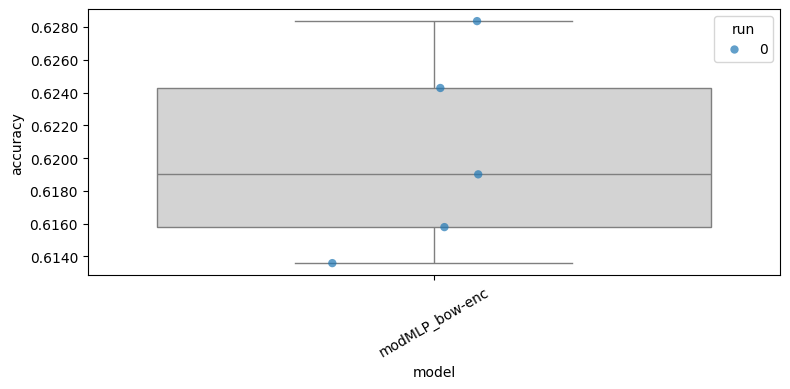

In [5]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [7]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [bow_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = mmlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=mmlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/modMLP_bow-enc/seed-{seed}/fold-{fold}/model"
        model = mmlp.load(model_folder)

        mmlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = mmlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.6899384850755744, 'accuracy': 0.573394495412844}
              precision    recall  f1-score   support

           0       0.61      0.38      0.46       428
           1       0.56      0.76      0.65       444

    accuracy                           0.57       872
   macro avg       0.58      0.57      0.55       872
weighted avg       0.58      0.57      0.56       872

{'loss': 0.6787832609010399, 'accuracy': 0.6032110091743119}
              precision    recall  f1-score   support

           0       0.62      0.51      0.56       428
           1       0.59      0.69      0.64       444

    accuracy                           0.60       872
   macro avg       0.61      0.60      0.60       872
weighted avg       0.60      0.60      0.60       872

{'loss': 0.6852778491623904, 'accuracy': 0.5802752293577982}
              precision    recall  f1-score   support

           0       0.58      0.50      0.54       428
           1       0.58      0.66      0.61       444

